<a href="https://colab.research.google.com/github/projet-virage/ActiveTransportation/blob/main/EnvironmentalBuilt_MostEfficientVersion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Latest Version of the Agent-Based Transportation Model: GitHub–Google Colab Integration and Synchronization Workflow

In [ ]:
!pip install mesa
!pip install osmnx
!pip install optuna
!pip install gower

In [2]:
from mesa import Model, Agent
from mesa.datacollection import DataCollector
from mesa.time import Schedule
import os

import geopandas as gpd
import networkx as nx
import osmnx
import numpy as np
import random
from shapely.geometry import Point
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.optimize import differential_evolution
import pandas as pd
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import time
import optuna
import math
from scipy.stats import truncnorm
import gower
from pathlib import Path
from collections import defaultdict

# Importing spatial data and preprocessing them

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
data_path = os.environ.get("DATA_FOLDER", "/content/drive/MyDrive/Transportation_UrbanHealth")
# Importing Census Data
df = pd.read_csv(os.path.join(data_path, "Census_data.csv")).iloc[1:,:]
gender = pd.read_csv(os.path.join(data_path, "Gender.csv")).drop(columns=['Population']).dropna().reset_index(drop=True)

# Importing Spatial Data
MTL_DA = gpd.read_file(os.path.join(data_path, "DA_MTL_MTM.shp"))[['UID_12','geometry']].rename(columns={'UID_12':'DA_name'})
residential = gpd.read_file(os.path.join(data_path, "Residential_MTM.shp"))
workplaces = gpd.read_file(os.path.join(data_path, "workplaces.shp"))
stm = gpd.read_file(os.path.join(data_path, "STM_MTM.shp"))
Bikelanes = gpd.read_file(os.path.join(data_path, "VQ_bikelanes.shp"))

# Nodes and Edges for the networks
Netnodes = gpd.read_file(os.path.join(data_path, "Nodes.shp"))
Netedges_car = gpd.read_file(os.path.join(data_path, "Edges_car.shp")).set_index(['u', 'v', 'key'])
Netedges_walk = gpd.read_file(os.path.join(data_path, "Edges_walk.shp")).set_index(['u', 'v', 'key'])
Netedges_bike = gpd.read_file(os.path.join(data_path, "Edges_bike.shp")).set_index(['u', 'v', 'key'])
Netedges_transit = gpd.read_file(os.path.join(data_path, "Edges_transit.shp")).set_index(['u', 'v', 'key'])

In [5]:
gender[['Male',	'Female']] = gender[['Male',	'Female']].apply(lambda x: x/(gender['Male'] + gender['Female']))

df_census_data = df.rename(columns={
    "COL0": "DA_name",
    "COL1": "population",
    "COL2": "age_15_64",
    "COL3": "income_no_total",
    "COL4": "income_under_10k",
    "COL5": "income_10k_20k",
    "COL6": "income_20k_30k",
    "COL7": "income_30k_40k",
    "COL8": "income_40k_50k",
    "COL9": "income_50k_60k",
    "COL10": "income_60k_70k",
    "COL11": "income_70k_80k",
    "COL12": "income_80k_90k",
    "COL13": "income_90k_100k",
    "COL15": "income_100k_150k",
    "COL16": "income_150k_plus",
    "COL17": "Car",
    "COL18": "Transit",
    "COL19": "Walk",
    "COL20": "Bike",
    "COL21": "Commute_other",
    "COL22": "commute_time_less_15",
    "COL23": "commute_time_15_30",
    "COL24": "commute_time_30_45",
    "COL25": "commute_time_45_60",
    "COL26": "commute_time_more_60"
})

df_census_data.drop(columns = "COL14", inplace = True)
df_census_data.dropna(inplace=True)

df_census_data['All_modes'] = df_census_data['Car'] + df_census_data['Transit'] + df_census_data['Walk'] + df_census_data['Bike']

df_census_data["Pop_with_income"] = df_census_data[['income_no_total', 'income_under_10k', 'income_10k_20k', "income_20k_30k", "income_30k_40k", "income_40k_50k","income_50k_60k",
                        "income_60k_70k", "income_70k_80k", "income_80k_90k", "income_90k_100k", "income_100k_150k", "income_150k_plus"]].sum(axis= 1)

# Percentage of each group
df_census_data[['income_no_total', 'income_under_10k', 'income_10k_20k', "income_20k_30k", "income_30k_40k", "income_40k_50k","income_50k_60k",
                        "income_60k_70k", "income_70k_80k", "income_80k_90k", "income_90k_100k", "income_100k_150k", "income_150k_plus"]]= df_census_data[['income_no_total', 'income_under_10k', 'income_10k_20k', "income_20k_30k", "income_30k_40k", "income_40k_50k","income_50k_60k",
                        "income_60k_70k", "income_70k_80k", "income_80k_90k", "income_90k_100k", "income_100k_150k", "income_150k_plus"]].apply(lambda x: x/df_census_data["Pop_with_income"])


df_census_data["income_no_total"] = 1 - df_census_data[['income_under_10k', 'income_10k_20k', "income_20k_30k", "income_30k_40k", "income_40k_50k","income_50k_60k",
                        "income_60k_70k", "income_70k_80k", "income_80k_90k", "income_90k_100k", "income_100k_150k", "income_150k_plus"]].sum(axis= 1)


df_census_data['commute_time_15_30'] = df_census_data['commute_time_less_15'] + df_census_data['commute_time_15_30']
df_census_data['Total_commuters'] = df_census_data['commute_time_15_30'] + df_census_data['commute_time_30_45'] + df_census_data['commute_time_45_60'] + df_census_data['commute_time_more_60']
df_census_data[['commute_time_15_30', 'commute_time_30_45', 'commute_time_45_60', 'commute_time_more_60']] = df_census_data[['commute_time_15_30', 'commute_time_30_45', 'commute_time_45_60', 'commute_time_more_60']].apply(lambda x: x/df_census_data["Total_commuters"])

df_census_data['commute_time_15_30'] = 1 - (df_census_data['commute_time_30_45'] + df_census_data['commute_time_45_60'] + df_census_data['commute_time_more_60'])
df_census_data.drop(columns=['Total_commuters','commute_time_less_15', "age_15_64","Commute_other", "Pop_with_income"], inplace=True)

Census_df = pd.merge(df_census_data, gender, how="left", on="DA_name")

# Merging the cencus data with the DA
montreal_da =pd.merge(MTL_DA, Census_df, on="DA_name", how= 'right').copy()
montreal_da["population"] = (pd.to_numeric(montreal_da["population"],errors="coerce").fillna(0).clip(lower=0))

In [6]:
montreal_da.columns

Index(['DA_name', 'geometry', 'population', 'income_no_total',
       'income_under_10k', 'income_10k_20k', 'income_20k_30k',
       'income_30k_40k', 'income_40k_50k', 'income_50k_60k', 'income_60k_70k',
       'income_70k_80k', 'income_80k_90k', 'income_90k_100k',
       'income_100k_150k', 'income_150k_plus', 'Car', 'Transit', 'Walk',
       'Bike', 'commute_time_15_30', 'commute_time_30_45',
       'commute_time_45_60', 'commute_time_more_60', 'All_modes', 'Male',
       'Female'],
      dtype='object')

# Creating Networks

In [7]:
nodex = Netnodes.join(Netnodes.get_coordinates()).set_index('nodeid')[['x', 'y', 'geometry']]

# Load network
netx_car = osmnx.graph_from_gdfs(nodex, Netedges_car)
netx_walk = osmnx.graph_from_gdfs(nodex, Netedges_walk)
netx_bike = osmnx.graph_from_gdfs(nodex, Netedges_bike)
netx_transit = osmnx.graph_from_gdfs(nodex, Netedges_transit)

# Plotting Network

In [ ]:
# Car network
fig, ax = osmnx.plot.plot_graph(netx_car, edge_alpha=.3, node_color="r", node_size=5, node_zorder=0, node_alpha=.2)

# Walk network
fig, ax = osmnx.plot.plot_graph(netx_walk, edge_alpha=.3, node_color="r", node_size=4, node_zorder=0, node_alpha=.2)

# Bike network
fig, ax = osmnx.plot.plot_graph(netx_bike, edge_alpha=.3, node_color="r", node_size=4, node_zorder=0, node_alpha=.2)

# Transit network
fig, ax = osmnx.plot.plot_graph(netx_transit, edge_alpha=.3, node_color="r", node_size=4, node_zorder=0, node_alpha=.2)

# Model development

In [8]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [12]:
# The main function
class TransportModel(Model):

  def __init__(self, n_rep, DA_MTL, Res, Net_car, Net_walk, Net_bike, Net_transit, Wrk_N, STM_N, bikelanes):
    super().__init__()
    self.agent_list = []
    self.Each_agent_represents = n_rep
    self.montreal_da = DA_MTL.copy()
    self.residential = Res.copy()
    self.betas = None
    self.bikelanes = bikelanes.copy()
    self.bikelane_sindex = self.bikelanes.sindex

    self.Gc = Net_car
    self.Gw = Net_walk
    self.Gb = Net_bike
    self.Gstm = Net_transit

    self.workplaces = Wrk_N.copy()
    self.stms = STM_N.copy()

    self.car_cache = {}
    self.walk_cache = {}
    self.transit_cache = {}
    self.bike_cache = {}


    # Add network nodes
    self.stms['network_node'] = osmnx.distance.nearest_nodes(self.Gw, self.stms.geometry.x, self.stms.geometry.y)
    self.stm_tree = cKDTree(np.column_stack([self.stms.geometry.x, self.stms.geometry.y]))
    #----------------------------------------------------------------------
    # Residential
    self.residential["res_id"] = np.arange(len(self.residential))

    x = self.residential.centroid.x.values
    y = self.residential.centroid.y.values

    self.residential["network_node"] = osmnx.distance.nearest_nodes(self.Gw, x, y)

    self.residential["x"] = x
    self.residential["y"] = y

    self.res_lookup = (self.residential.set_index("res_id")[["network_node", "x", "y"]].to_dict("index"))
    #----------------------------------------------------------------------
    # Workplaces
    self.workplaces["wrk_id"] = np.arange(len(self.workplaces))

    # Workplace coordinates
    self.workplaces["x"] = self.workplaces.geometry.x
    self.workplaces["y"] = self.workplaces.geometry.y

    xw = self.workplaces.geometry.x.values
    yw = self.workplaces.geometry.y.values

    self.workplaces["network_node"] = osmnx.distance.nearest_nodes(self.Gw, xw, yw)
    self.wrk_lookup = (self.workplaces.set_index("wrk_id")[["network_node", "x", "y"]].to_dict("index"))
    # Workplace KDTree
    self.workplace_tree = cKDTree(np.column_stack([self.workplaces.geometry.x, self.workplaces.geometry.y]))
    #-----------------------------------------------------------------------------------------
    # Create agents
    self.create_agents()

    # Assigning local population density
    self.assign_local_population_density()

    # Activate agents in random order
    for agentt in tqdm(random.sample(self.agent_list, len(self.agent_list)), desc= "Agents activation"):
      agentt.step()

    self.compute_all_travel_times(self.agent_list)

    # prepare static variables and statistics once
    self.prepare_static_calibration_data()

  # --------------------------------------------------------
  def closest_candidate_node(self, G, source_node, candidate_gdf, tree):

    source_xy = (G.nodes[source_node]['x'],G.nodes[source_node]['y'])

    distance, idx = tree.query(source_xy)
    return candidate_gdf.iloc[idx]['network_node']
  # --------------------------------------------------------
  def create_agents(self):

    pbar = tqdm(self.montreal_da.iterrows(), total=len(self.montreal_da))
    for _, da in pbar:
      pbar.set_description(f"Creating agents for DA: {da['DA_name']}")

      if da['Car'] == 0 and da['Transit'] == 0 and da['Bike'] == 0 and da['Walk'] == 0:
        continue

      else:
        # Residential polygons inside this DA
        res = self.residential[self.residential.intersects(da.geometry)]
        if res.empty:
          continue


        agents_with_DAs =[]
        # Initializing Agents (age_15–64)
        num_adults = round((da['Car'] / self.Each_agent_represents)) + round((da['Transit'] / self.Each_agent_represents))+ round((da['Bike'] / self.Each_agent_represents)) + round((da['Walk'] / self.Each_agent_represents))

        male_num = round(da['Male'] * num_adults)
        female_num = num_adults - male_num

        # Male initialization
        for _ in range(male_num):

          poly = res.iloc[[np.random.randint(len(res))]]

          agent = PersonAgent(self, {
              'age': random.randint(15, 64),
              'gender': 1,
              'age_group': 'adult',
              'DA_ID': da['DA_name'],
              'income': 0,
              'res_id': poly['res_id'].values[0],
              'x': poly.geometry.centroid.x.values[0],
              'y': poly.geometry.centroid.y.values[0],
              'proximity_to_bikelane': None,
              'commute_distance': None,
              'pop_dens': np.nan
              })

          self.agent_list.append(agent)
          agents_with_DAs.append(agent)

        # Female initialization
        for _ in range(female_num):
          poly = res.iloc[[np.random.randint(len(res))]]

          agent = PersonAgent(self, {
              'age': random.randint(15, 64),
              'gender': 0,
              'age_group': 'adult',
              'DA_ID': da['DA_name'],
              'income': 0,
              'res_id': poly['res_id'].values[0],
              'x': poly.geometry.centroid.x.values[0],
              'y': poly.geometry.centroid.y.values[0],
              'proximity_to_bikelane': None,
              'commute_distance': None,
              'pop_dens': np.nan
          })

          self.agent_list.append(agent)
          agents_with_DAs.append(agent)

        # Calculating the number of the agents in each coomute group

        num_agents_wit_commute_time_30_45 = math.floor(da['commute_time_30_45'] * num_adults)
        num_agents_wit_commute_time_45_60 = math.floor(da['commute_time_45_60'] * num_adults)
        num_agents_wit_commute_time_more_60 = math.floor(da['commute_time_more_60'] * num_adults)
        num_agents_wit_commute_time_15_30 = num_adults - (num_agents_wit_commute_time_30_45 + num_agents_wit_commute_time_45_60 + num_agents_wit_commute_time_more_60)

        commute_categories = (
            [4000] * num_agents_wit_commute_time_15_30 +
            [8000] * num_agents_wit_commute_time_30_45 +
            [13000] * num_agents_wit_commute_time_45_60 +
            [18000] * num_agents_wit_commute_time_more_60
        )

        # Randomize which agent receives which category
        random.shuffle(commute_categories)

        for agent, category in zip(agents_with_DAs, commute_categories):
          agent.commute_distance = category


        # Calculating the number of the agents in each income group and randomly setting values to income attribute of corresponding agent

        num_income_under_10k = math.floor(da['income_under_10k'] * num_adults)
        num_income_10k_20k = math.floor(da['income_10k_20k'] * num_adults)
        num_income_20k_30k = math.floor(da['income_20k_30k'] * num_adults)
        num_income_30k_40k = math.floor(da['income_30k_40k'] * num_adults)
        num_income_40k_50k = math.floor(da['income_40k_50k'] * num_adults)
        num_income_50k_60k = math.floor(da['income_50k_60k'] * num_adults)
        num_income_60k_70k = math.floor(da['income_60k_70k'] * num_adults)
        num_income_70k_80k = math.floor(da['income_70k_80k'] * num_adults)
        num_income_80k_90k = math.floor(da['income_80k_90k'] * num_adults)
        num_income_90k_100k = math.floor(da['income_90k_100k'] * num_adults)
        num_income_100k_150k = math.floor(da['income_100k_150k'] * num_adults)
        num_income_150k_plus = math.floor(da['income_150k_plus'] * num_adults)

        num_without_income = num_adults - (num_income_under_10k + num_income_10k_20k + num_income_20k_30k + num_income_30k_40k +
                                           num_income_40k_50k + num_income_50k_60k + num_income_60k_70k + num_income_70k_80k + num_income_80k_90k +
                                           num_income_90k_100k + num_income_100k_150k + num_income_150k_plus)

        income_categories = (
            ["without_income"] * num_without_income +
            ["under_10k"] * num_income_under_10k +
            ["10k_20k"] * num_income_10k_20k +
            ["20k_30k"] * num_income_20k_30k +
            ["30k_40k"] * num_income_30k_40k +
            ["40k_50k"] * num_income_40k_50k +
            ["50k_60k"] * num_income_50k_60k +
            ["60k_70k"] * num_income_60k_70k +
            ["70k_80k"] * num_income_70k_80k +
            ["80k_90k"] * num_income_80k_90k +
            ["90k_100k"] * num_income_90k_100k +
            ["100k_150k"] * num_income_100k_150k +
            ["150k_plus"] * num_income_150k_plus
        )

        # Randomize which agent receives which category
        random.shuffle(income_categories)


        # ---------------------------------------------------------
        # Defining the normal distribution for each category

        income_distributions = {
            "without_income": (0,      0,      0,      0),
            "under_10k":  (0,      9999,   5000,   2500),
            "10k_20k":    (10000,  19999,  15000,  2500),
            "20k_30k":    (20000,  29999,  25000, 2500),
            "30k_40k":    (30000,  39999,  35000, 2500),
            "40k_50k":    (40000,  49999,  45000, 2500),
            "50k_60k":    (50000,  59999,  55000, 2500),
            "60k_70k":    (60000,  69999,  65000, 2500),
            "70k_80k":    (70000,  79999,  75000, 2500),
            "80k_90k":    (80000,  89999,  85000, 2500),
            "90k_100k":   (90000,  99999,  95000, 2500),
            "100k_150k":  (100000, 149999, 125000, 12500),
            "150k_plus":  (150000, 250000, 175000, 25000)
        }


        # ---------------------------------------------------------

        for agent, category in zip(agents_with_DAs, income_categories):
          if category == "without_income":
            agent.income = 0
          else:
            low, high, mean, std = income_distributions[category]

            # Truncated normal: guarantees income stays within category
            a = (low - mean) / std
            b = (high - mean) / std

            agent.income = round(truncnorm.rvs(a, b,loc=mean,scale=std))

  # ================================================
  def assign_local_population_density(self):
    agents = self.agent_list

    # Residential coordinates of all agents
    coords = np.array([[agent.x, agent.y] for agent in agents])

    # Spatial index
    tree = cKDTree(coords)

    radius = 1000  # 1 km in metres

    # Number of agents within 1 km of each agent
    counts = tree.query_ball_point(coords, r=radius, return_length=True)

    # Convert buffer area to km²
    area_km2 = np.pi * (radius / 1000)**2

    # Calculate population density
    densities = (counts * self.Each_agent_represents) / area_km2

    # Assign density to each agent
    for agent, density in zip(agents, densities):
        agent.pop_dens = density

  def compute_mode_shares(self):
    return self.fast_compute_mode_shares()


  # ==============================================================
  def _batch_shortest(self, G, origins, destinations, weight, cache):

    results = np.empty(len(origins), dtype=float)

    missing = {}

    for i, (o, d) in enumerate(zip(origins, destinations)):

        key = (o, d)

        if key in cache:
            results[i] = cache[key]

        else:
            missing.setdefault(key, []).append(i)


    if len(missing) == 0:
        return results

    unique_origins = [k[0] for k in missing]
    unique_destinations = [k[1] for k in missing]

    # Single CPU environment
    paths = osmnx.routing.shortest_path(G,unique_origins,unique_destinations,weight=weight,cpus=1)

    for path, key in zip(paths, missing.keys()):

        if path is None:
            dist = np.nan
        else:
            dist = nx.path_weight(
                G,
                path,
                weight=weight
            )

        cache[key] = dist

        for idx in missing[key]:
            results[idx] = dist


    return results

  # ==============================================================
  def compute_all_travel_times(self, agents):
    # CAR: home -----> work

    t0 = time.perf_counter()
    total_steps = 4
    stp = 1
    print(f"[{stp}/{total_steps}] Computing car travel times...")

    car_times = self._batch_shortest(self.Gc, [a.home_node_network for a in agents], [a.workplace_node_network for a in agents],"trv_time", self.car_cache)

    for a, t in zip(agents, car_times):
        a.time_car = t
        a.auto_available = np.isfinite(t)

    print(f"Done ({time.perf_counter() - t0:.1f} s)")
    #--------------------------------------------------------------------------------------------------------------------

    t1 = time.perf_counter()
    stp += 1
    print(f"[{stp}/{total_steps}] Computing walking travel times...")
    # ---------- WALK: home -> work ----------
    walk_times = self._batch_shortest(self.Gw,[a.home_node_network for a in agents],[a.workplace_node_network for a in agents],"trv_time", self.walk_cache)

    for a, t in zip(agents, walk_times):
      a.time_walk = t
      a.walk_available = np.isfinite(t)

    print(f"Done ({time.perf_counter() - t1:.1f} s)")


    #-----------------------------------------------------------------------------------------------------------------
    t2 = time.perf_counter()
    stp += 1
    print(f"[{stp}/{total_steps}] Computing STM travel times...")
    # ---------- STM: home -> home_stm_node ----------
    home_stm_times = self._batch_shortest(self.Gw,[a.home_node_network for a in agents],[a.home_stm_node_network for a in agents],"trv_time", self.walk_cache)

    # Keep only agents with reachable home -> STM
    valid_agents = []

    for a, t in zip(agents, home_stm_times):
      a.time_home_stm = t
      a.transit_available = False   # default

      if np.isfinite(t):
        valid_agents.append(a)

    # ==============================================================
    #---------- STM: home_stm_node -> work_stm_node ----------
    valid_agents_2 = []
    if len(valid_agents) > 0:
      stm_stm_times = self._batch_shortest(self.Gstm,[a.home_stm_node_network for a in valid_agents],[a.work_stm_node_network for a in valid_agents],"trv_time", self.transit_cache)

      valid_agents_2 = []

      for a, t in zip(valid_agents, stm_stm_times):
        a.time_stm_stm = t

        if np.isfinite(t):
          valid_agents_2.append(a)

    # ---------- STM: work_stm_node -> workplace ----------
    if len(valid_agents_2) > 0:

      stm_work_times = self._batch_shortest(self.Gw,[a.work_stm_node_network for a in valid_agents_2],[a.workplace_node_network for a in valid_agents_2],"trv_time", self.walk_cache)

      for a, t in zip(valid_agents_2, stm_work_times):
        a.time_stm_work = t

        if np.isfinite(t):
          a.transit_available = True

    print(f"Done ({time.perf_counter() - t2:.1f} s)")

    #-----------------------------------------------------------------------------------------------------------------


    t3 = time.perf_counter()
    stp += 1
    print(f"[{stp}/{total_steps}] Computing BIKE travel times...")
    # ---------- BIKE: home -> home ----------
    bike_times = self._batch_shortest(self.Gb,[a.home_node_network for a in agents],[a.workplace_node_network for a in agents],"trv_time", self.bike_cache)

    for a, t in zip(agents, bike_times):
      a.time_bike = t
      a.bike_available = np.isfinite(t)
    print(f"Done ({time.perf_counter() - t3:.1f} s)")


  def prepare_static_calibration_data(self):

    agents = self.agent_list

    cols = ('time_car','time_home_stm','time_stm_stm','time_stm_work','time_bike','time_walk','income','age','pop_dens','proximity_to_bikelane')
    df = pd.DataFrame({c: [getattr(a, c) for a in agents] for c in cols})

    # Total transit travel time
    df['time_transit'] = (df['time_home_stm']+ df['time_stm_stm']+ df['time_stm_work'])

    self.static_agent_df = df
    self.standardization_stats = {}

    # COMMON STANDARDIZATION FOR ALL TRAVEL TIMES
    time_columns = ['time_car','time_transit','time_bike','time_walk']

    # Combine all four transportation travel-time distributions
    all_times = np.concatenate([pd.to_numeric(df[col],errors='coerce').to_numpy(dtype=float) for col in time_columns])

    # Exclude NaN and infinite values
    all_times = all_times[np.isfinite(all_times)]

    if len(all_times) > 0:
        time_mean = float(all_times.mean())
        time_std = float(all_times.std())
    else:
        time_mean = 0.0
        time_std = 0.0

    # Assign the SAME statistics to all four modes
    for col in time_columns:
        self.standardization_stats[col] = (time_mean,time_std)

    # STANDARDIZATION FOR OTHER VARIABLES
    other_columns = ['income','age','pop_dens','proximity_to_bikelane']

    for col in other_columns:
        v = pd.to_numeric(df[col],errors='coerce').to_numpy(dtype=float)
        v = v[np.isfinite(v)]

        if len(v) > 0:
            mean = float(v.mean())
            std = float(v.std())
        else:
            mean = 0.0
            std = 0.0

        self.standardization_stats[col] = (mean,std)

    # DA ------> AGENT INDEX MAPPING

    self.agents_by_da = defaultdict(list)

    for i, a in enumerate(agents):
        if a.age_group == 'adult':
            self.agents_by_da[a.DA_ID].append(i)


  def standardized(self, value, name):
      if pd.isna(value):
          return np.nan
      mean, std = self.standardization_stats[name]
      return (value - mean) / std if std > 0 else 0.0



  def compute_mode_shares(self):
    results = {}

    modes = ["auto", "transit", "bike", "walk"]

    for da_id, indices in self.agents_by_da.items():
        choices = [self.agent_list[i].mode_choice for i in indices]
        counts = {mode: choices.count(mode) for mode in modes}
        results[da_id] = counts

    return results



  def model_step(self):
      df = self.static_agent_df

      for agent in self.agent_list:
          agent.compute_mode_choice(self.betas, df)


In [13]:
class PersonAgent(Agent):

  def __init__(self, model, attrs):
    super().__init__(model)
    # Demographic
    self.age = attrs['age']
    self.age_group = attrs['age_group']
    self.gender = attrs['gender']
    self.DA_ID = attrs['DA_ID']
    self.income = attrs.get('income', None)
    self.x = attrs['x']
    self.y = attrs['y']
    self.commute_distance = attrs['commute_distance']
    self.pop_dens = attrs['pop_dens']
    self.proximity_to_bikelane = attrs['proximity_to_bikelane']
    self.res_id = attrs['res_id']
    self.work_id = None
    self.work_x = np.nan
    self.work_y = np.nan

    # Network home and workplace nodes
    self.home_node_network = None
    self.workplace_node_network = None

    # Closest stm node to home and workplace
    self.home_stm_node_network = None
    self.work_stm_node_network = None


    # Travel times under different transportation modes
    self.time_car = np.nan

    self.time_home_stm = np.nan
    self.time_stm_stm = np.nan
    self.time_stm_work = np.nan

    self.time_bike = np.nan

    self.time_walk = np.nan

    # To avoid repetitions
    self.time_auto_st = np.nan
    self.time_transit_st = np.nan
    self.time_bike_st = np.nan
    self.time_walk_st = np.nan
    self.income_st = np.nan
    self.age_st = np.nan
    self.population_density_st = np.nan
    self.prx_bikelanes_st = np.nan

    # Availability of the transportation mode
    self.auto_available = False
    self.walk_available = False
    self.transit_available = False
    self.bike_available = False

    self.U_auto = 0.0
    self.U_transit = 0.0
    self.U_bike = 0.0
    self.U_walk = 0.0

    # Mode
    self.mode_choice = None
  # --------------------------------------------------------
  def step(self):
    self.assign_nodes()

  # --------------------------------------------------------
  def workplaces_within_radius(self, x,y, radius):
    nearby_indices = self.model.workplace_tree.query_ball_point([x, y],r=radius)

    if not nearby_indices:
        return None

    idx = random.choice(nearby_indices)

    return self.model.workplaces.iloc[idx]["wrk_id"]
  # --------------------------------------------------------
  def assign_nodes(self):

    # HOME
    home = self.model.res_lookup[self.res_id]
    self.home_node_network = home["network_node"]
    self.x = home["x"]
    self.y = home["y"]

    # Distance to nearest bicycle lane
    point = Point(self.x, self.y)
    nearest_idx = self.model.bikelane_sindex.nearest(point,return_all=False)
    idx = int(nearest_idx[1][0])
    self.proximity_to_bikelane = (self.model.bikelanes.geometry.iloc[idx].distance(point))

    # WORKPLACE
    if self.age_group == "adult":
        self.work_id = self.workplaces_within_radius(self.x,self.y,self.commute_distance)

        if self.work_id is not None:
            wrk = self.model.wrk_lookup[self.work_id]
            self.workplace_node_network = wrk["network_node"]
            self.work_x = wrk["x"]
            self.work_y = wrk["y"]

    # STM candidate nodes
    self.home_stm_node_network = (self.model.closest_candidate_node(self.model.Gw,self.home_node_network,self.model.stms,self.model.stm_tree))

    if self.workplace_node_network is not None:
        self.work_stm_node_network = (self.model.closest_candidate_node(self.model.Gw,self.workplace_node_network,self.model.stms,self.model.stm_tree))

  # --------------------------------------------------------
  def compute_mode_choice(self, betas, df):
    (
    β1,   # time_auto
    β2,   # age_auto
    β3,   # gender
    β4,   # income_auto
    β5,   # population_density
    β6,   # age × time_auto
    β7,   # income × time_auto

    β8,   # time_transit
    β9,   # age_transit
    β10,   # gender
    β11,   # income_transit
    β12,   # population_density
    β13,   # age × time_transit
    β14,  # income × time_transit

    β15,  # time_bike
    β16,  # age_bike
    β17,   # gender
    β18,  # income_bike
    β19,   # population_density
    β20,  # proximity_to_bikelane
    β21,  # age × time_bike
    β22,  # income × time_bike

    β23,  # time_walk
    β24,  # age_walk
    β25,   # gender
    β26,  # income_walk
    β27,   # population_density
    β28,  # age × time_walk
    β29,  # income × time_walk


    ASC_auto,
    ASC_transit,
    ASC_bike) = betas

    # Z-score standardization
    ###########################################################

    def safe_standardize(value, variable_name):
        return self.model.standardized(value, variable_name)

    # Standardization of the variables
    self.time_auto_st = safe_standardize(self.time_car, 'time_car')
    self.time_transit_st = safe_standardize(self.time_home_stm + self.time_stm_stm + self.time_stm_work,'time_transit')
    self.time_bike_st = safe_standardize(self.time_bike,"time_bike")
    self.time_walk_st = safe_standardize(self.time_walk,"time_walk")

    self.income_st = safe_standardize(self.income, "income")
    self.age_st = safe_standardize(self.age, "age")
    self.population_density_st = safe_standardize(self.pop_dens, "pop_dens")
    self.prx_bikelanes = safe_standardize(self.proximity_to_bikelane, "proximity_to_bikelane")

    # Verifying if there is any Nan in the values
    if np.isnan(self.time_auto_st):
      self.auto_available = False
      self.U_auto = -np.inf

    if np.isnan(self.time_transit_st):
      self.transit_available = False
      self.U_transit = -np.inf

    if np.isnan(self.time_bike_st):
      self.bike_available = False
      self.U_bike = -np.inf

    if np.isnan(self.time_walk_st):
      self.walk_available = False
      self.U_walk = -np.inf

    # Utilities
    if self.auto_available == True:
      self.U_auto = (ASC_auto
                + β1 * self.time_auto_st
                + β2 * self.age_st
                + β3 * self.gender
                + β4 * self.income_st
                + β5 * self.population_density_st
                + β6 * self.age_st * self.time_auto_st
                + β7 * self.income_st * self.time_auto_st
                )
    else:
      self.U_auto = -np.inf

    if self.transit_available == True:
      self.U_transit = (
          ASC_transit
          + β8 * self.time_transit_st
          + β9 * self.age_st
          + β10 * self.gender
          + β11 * self.income_st
          + β12 * self.population_density_st
          + β13 * self.age_st * self.time_transit_st
          + β14 * self.income_st * self.time_transit_st)
    else:
      self.U_transit = -np.inf

    if self.bike_available == True:
      self.U_bike = (
          ASC_bike
        + β15 * self.time_bike_st
        + β16 * self.age_st
        + β17 * self.gender
        + β18 * self.income_st
        + β19 * self.population_density_st
        + β20 * self.prx_bikelanes
        + β21 * self.age_st * self.time_bike_st
        + β22 * self.income_st * self.time_bike_st)
    else:
      self.U_bike = -np.inf

    if self.walk_available == True:
      self.U_walk = (
          β23 * self.time_walk_st
        + β24 * self.age_st
        + β25 * self.gender
        + β26 * self.income_st
        + β27 * self.population_density_st
        + β28 * self.age_st * self.time_walk_st
        + β29 * self.income_st * self.time_walk_st)
    else:
      self.U_walk = -np.inf



    # Calculation of probabilities
    utilities = np.array([self.U_auto, self.U_transit, self.U_bike, self.U_walk])

    exp_u = np.exp(utilities)
    sum_exp = np.sum(exp_u)

    modes = ["auto", "transit", "bike", "walk"]

    if sum_exp == 0 or np.isnan(sum_exp) or np.isinf(sum_exp):
      self.mode_choice = random.choice(["auto", "transit", "bike", "walk"])
    else:
      probs = exp_u / sum_exp
      self.mode_choice = modes[np.argmax(probs)]

#Considering each agent as the represener of 50 people

In [14]:
# Initialize the transport model
Transport_model = TransportModel(n_rep = 50, DA_MTL = montreal_da, Res = residential, Net_car = netx_car, Net_walk = netx_walk, Net_bike = netx_bike,  Net_transit= netx_transit, Wrk_N = workplaces, STM_N = stm, bikelanes=Bikelanes)


Agents activation: 100%|██████████| 12340/12340 [01:58<00:00, 103.92it/s]


[1/4] Computing car travel times...
Done (85.3 s)
[2/4] Computing walking travel times...
Done (114.5 s)
[3/4] Computing STM travel times...
Done (69.7 s)
[4/4] Computing BIKE travel times...
Done (116.4 s)


# Calibration

In [15]:
def calibration_error(betas, model, n_steps=1, save_results=False):

  model.betas = betas

  Stime = time.perf_counter()
  # calculate all four utilities
  model.model_step()

  Etime = time.perf_counter()
  exe_time = Etime - Stime
  print(f"\nExecution time for {n_steps} steps: {exe_time:.4f} seconds")

  sim = model.compute_mode_shares()

  total_error = 0.0
  total_weight = 0.0

  calibration_records = []

  observed_global = np.zeros(4)
  simulated_global = np.zeros(4)


  da_iterator = model.montreal_da.iterrows()

  if save_results:
    da_iterator = tqdm(da_iterator,total=len(model.montreal_da),desc="Calibrating DAs")

  for _, da in da_iterator:

      if (da["Car"] == 0 and da["Transit"] == 0 and da["Bike"] == 0 and da["Walk"] == 0):
          continue

      da_id = da["DA_name"]

      if da_id not in model.agents_by_da:
          continue

      if da_id not in sim:
          continue

      observed_counts = np.array([
          round(da["Car"] / model.Each_agent_represents),
          round(da["Transit"] / model.Each_agent_represents),
          round(da["Bike"] / model.Each_agent_represents),
          round(da["Walk"] / model.Each_agent_represents)
      ], dtype=float)

      simulated_counts = np.array([
          sim[da_id]["auto"],
          sim[da_id]["transit"],
          sim[da_id]["bike"],
          sim[da_id]["walk"]
      ], dtype=float)

      observed_global += observed_counts
      simulated_global += simulated_counts

      obs_total = observed_counts.sum()
      sim_total = simulated_counts.sum()

      if obs_total == 0 or sim_total == 0:
          continue

      observed_share = observed_counts / obs_total
      simulated_share = simulated_counts / sim_total

      share_error = np.mean((observed_share - simulated_share) ** 2)

      total_error += obs_total * share_error
      total_weight += obs_total

      # Store detailed results only when requested
      if save_results:

          calibration_records.append({

              "DA_name": da_id,

              "Obs_Auto": observed_counts[0],
              "Obs_Transit": observed_counts[1],
              "Obs_Bike": observed_counts[2],
              "Obs_Walk": observed_counts[3],

              "Sim_Auto": simulated_counts[0],
              "Sim_Transit": simulated_counts[1],
              "Sim_Bike": simulated_counts[2],
              "Sim_Walk": simulated_counts[3],

              "Error": share_error
          })

  # Global penalties

  if total_weight == 0:
      return np.inf

  if observed_global.sum() == 0 or simulated_global.sum() == 0:
      return np.inf

  local_error = total_error / total_weight

  obs_share_global = (observed_global / observed_global.sum())
  sim_share_global = (simulated_global / simulated_global.sum())

  global_share_error = np.mean((obs_share_global - sim_share_global) ** 2)

  final_error = (0.2 * local_error + 0.8 * global_share_error)

  # Save results

  if save_results:

      calibration_df = pd.DataFrame(calibration_records)

      calibration_df.to_csv("/content/drive/MyDrive/Transportation_UrbanHealth/DA_calibration_results.csv",index=False)

      print("\nObserved totals:")
      print(observed_global.astype(int))

      print("\nSimulated totals:")
      print(simulated_global.astype(int))

      print("\nObserved global:", observed_global.sum())
      print("Simulated global:", simulated_global.sum())

      print("\nObserved modal shares:")
      print(np.round(obs_share_global, 3))

      print("\nSimulated modal shares:")
      print(np.round(sim_share_global, 3))

      print("\nLocal error:", local_error)
      print("Global share error:", global_share_error)
      print("Final objective:", final_error)

      modes = ["Auto", "Transit", "Bike", "Walk"]

      x = np.arange(len(modes))
      width = 0.35

      plt.figure(figsize=(8, 6))

      plt.bar(
          x - width / 2,
          observed_global,
          width,
          label="Observed"
      )

      plt.bar(
          x + width / 2,
          simulated_global,
          width,
          label="Simulated"
      )

      plt.xticks(x, modes)
      plt.ylabel("Number of people")

      plt.title(
          "Observed vs Simulated Transportation Modes"
      )

      plt.grid(axis="y", alpha=0.3)
      plt.legend()
      plt.tight_layout()
      plt.show()

  return final_error

[I 2026-10-27 15:17:14,525] A new study created in memory with name: no-name-d2008f1a-4714-4f32-bcbb-85b937d62a99



Execution time for 1 steps: 0.4995 seconds


[I 2026-10-27 15:17:15,372] Trial 0 finished with value: 0.1480318645488557 and parameters: {'β1': -1.269646768247643, 'β2': -0.07392854038512575, 'β3': 0.6959818254342154, 'β4': 0.8979877262955549, 'β5': -1.2659720393363452, 'β6': -0.8440054796637974, 'β7': -0.9419163878318005, 'β8': -0.3109565157388765, 'β9': 0.9016725176148133, 'β10': 0.6242177333881367, 'β11': -1.4691232585562963, 'β12': 1.4548647782429915, 'β13': -0.16755735919957826, 'β14': -0.7876608893217238, 'β15': -1.645441313946154, 'β16': -1.2248932352198492, 'β17': -0.5872732711213868, 'β18': -0.7128653525516433, 'β19': 0.6479175279631737, 'β20': -1.0660685811049175, 'β21': -0.38814710527762053, 'β22': -0.8605061393479582, 'β23': -1.4303179353563245, 'β24': -0.9504572350594624, 'β25': -0.13179004734889221, 'β26': -0.3222360579104797, 'β27': 0.2995106732375396, 'β28': -0.4857655615863884, 'β29': -0.40758543113795753, 'ASC_auto': -2.721297523680014, 'ASC_transit': 1.860358815211507, 'ASC_bike': -3.6358070105016678}. Best is 


-----------------------------
Trial: 0
MSE: 0.148032
Betas:
[-1.26964677 -0.07392854  0.69598183  0.89798773 -1.26597204 -0.84400548
 -0.94191639 -0.31095652  0.90167252  0.62421773 -1.46912326  1.45486478
 -0.16755736 -0.78766089 -1.64544131 -1.22489324 -0.58727327 -0.71286535
  0.64791753 -1.06606858 -0.38814711 -0.86050614 -1.43031794 -0.95045724
 -0.13179005 -0.32223606  0.29951067 -0.48576556 -0.40758543 -2.72129752
  1.86035882 -3.63580701]

Execution time for 1 steps: 0.5435 seconds


[I 2026-10-27 15:17:16,282] Trial 1 finished with value: 0.14708754631065435 and parameters: {'β1': -1.873149393678705, 'β2': -0.07667169412000008, 'β3': 1.396896099223678, 'β4': 1.2125960221746916, 'β5': -1.043079346239944, 'β6': -0.9023278859936161, 'β7': -0.3157669734878431, 'β8': -1.1417026372077774, 'β9': 0.18305735226716824, 'β10': -0.014469269666189444, 'β11': -1.4484172183271724, 'β12': 1.3639806031181732, 'β13': -0.7412200183999831, 'β14': -0.33747771564601803, 'β15': -1.3921634016256488, 'β16': -0.7198979682332838, 'β17': 0.14013083802983894, 'β18': -1.2227183167117095, 'β19': 1.4543769416468377, 'β20': -0.3450520931919394, 'β21': -0.060501058435810884, 'β22': -0.10517264957235117, 'β23': -0.8340950413183841, 'β24': -0.11718864746532476, 'β25': -1.2345224938442416, 'β26': -1.2060257063712823, 'β27': 0.0678409333658071, 'β28': -0.6746696692367357, 'β29': -0.611322710310518, 'ASC_auto': -1.3719058093566245, 'ASC_transit': 3.6299000732154347, 'ASC_bike': -2.1459733864512858}. Be

...


-----------------------------
Trial: 28
MSE: 0.031459
Betas:
[-0.33444463 -0.93069276  0.26648369  0.74867103 -1.377135   -0.19863345
 -0.01723074 -0.62783923  1.18803143 -0.94776614 -1.44321657  1.49810959
 -0.497911   -0.92823428 -1.9726006  -0.95584362 -1.16144868 -1.10861343
  0.99236966 -0.84122007 -0.31185503 -0.86100621 -1.23696796 -0.1136766
 -0.96973739 -0.36653903  1.14912126 -0.87562871 -0.79217395 -0.37669725
  0.75471859 -3.69700578]

Execution time for 1 steps: 0.5218 seconds


[I 2026-10-27 15:17:40,453] Trial 29 finished with value: 0.0198351992919969 and parameters: {'β1': -0.5500307469918718, 'β2': -0.9717436408462057, 'β3': -0.14054228921295853, 'β4': 1.2304017637856859, 'β5': -0.953619785840231, 'β6': -0.25740927124489976, 'β7': -0.3224522971965673, 'β8': -0.6938608853113624, 'β9': 1.2349071032508088, 'β10': -0.5598623011169679, 'β11': -1.2231329203950192, 'β12': 1.437463880918892, 'β13': -0.006115869500963378, 'β14': -0.8084775196996924, 'β15': -1.551765711447906, 'β16': -1.2661891823425275, 'β17': -1.4605180988273356, 'β18': -0.6419160878924424, 'β19': 1.4431197817644854, 'β20': -1.129491654253311, 'β21': -0.1216189038761635, 'β22': -0.6592522564773879, 'β23': -0.5259243446110029, 'β24': -0.2659666042274482, 'β25': -1.3715021050899567, 'β26': -0.3615600022448882, 'β27': 0.9758635553438754, 'β28': -0.7123018921842024, 'β29': -0.7364412445368849, 'ASC_auto': 1.9323056006006207, 'ASC_transit': 1.8237303280956119, 'ASC_bike': -3.3860812021065803}. Best is


-----------------------------
Trial: 29
MSE: 0.019835
Betas:
[-0.55003075 -0.97174364 -0.14054229  1.23040176 -0.95361979 -0.25740927
 -0.3224523  -0.69386089  1.2349071  -0.5598623  -1.22313292  1.43746388
 -0.00611587 -0.80847752 -1.55176571 -1.26618918 -1.4605181  -0.64191609
  1.44311978 -1.12949165 -0.1216189  -0.65925226 -0.52592434 -0.2659666
 -1.37150211 -0.36156     0.97586356 -0.71230189 -0.73644124  1.9323056
  1.82373033 -3.3860812 ]

Execution time for 1 steps: 0.5601 seconds


Calibrating DAs: 100%|██████████| 3182/3182 [00:00<00:00, 9122.82it/s]



Observed totals:
[7888 3477  161  814]

Simulated totals:
[8674 3032   53  581]

Observed global: 12340.0
Simulated global: 12340.0

Observed modal shares:
[0.639 0.282 0.013 0.066]

Simulated modal shares:
[0.703 0.246 0.004 0.047]

Local error: 0.04882933693801651
Global share error: 0.0014476613456128225
Final objective: 0.01092399646409356


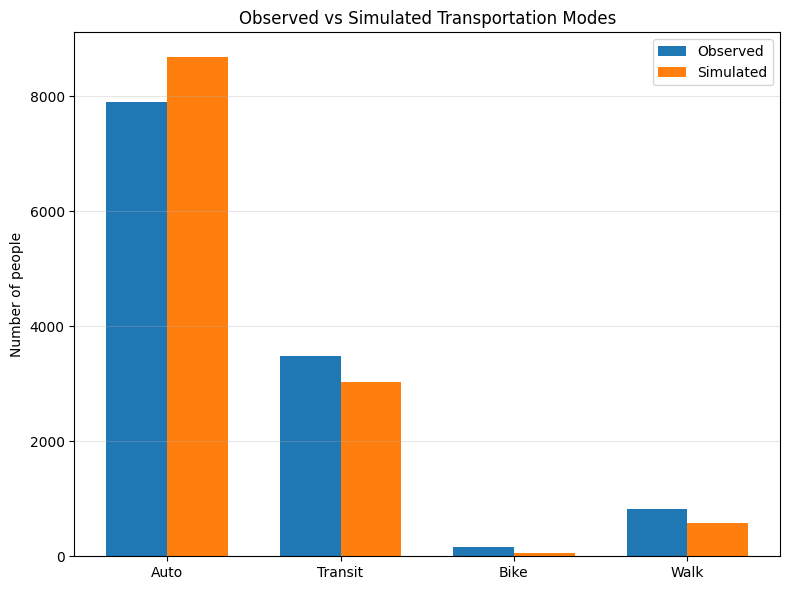


Optimization finished

Best MSE:
0.01096322191171241

Optimized coefficients:
[-0.69732516 -1.11561397  0.56155225  0.81748787 -0.32599678 -0.22943365
 -0.15117403 -0.34341192  0.97277363 -0.76296013 -0.82095757  1.37324683
 -0.70342258 -0.60101977 -1.99524433 -0.14289182 -1.05592679 -0.86800581
  0.79138742 -1.40695964 -0.19950241 -0.83046482 -0.48701135 -0.26549198
 -0.75521648 -0.52924295  1.12118172 -0.48301398 -0.47171498  0.67763361
 -0.24092655 -3.06478115]


In [16]:
mse_history = []
beta_history = []


def objective(trial):

    Sugg_betas = np.array([

    # =========================================================
    # AUTO
    # =========================================================

    trial.suggest_float("β1", -2.0, -0.05),      # time_auto → NEGATIVE
    trial.suggest_float("β2", -1.5,  0.0),       # age_auto → NEGATIVE
    trial.suggest_float("β3", -1.5,  1.5),       # gender_auto → depends on coding
    trial.suggest_float("β4",  0.0,  1.5),       # income_auto → POSITIVE
    trial.suggest_float("β5", -1.5,  0.0),       # population_density_auto → NEGATIVE

    trial.suggest_float("β6", -1.0,  0.0),       # age × time_auto → NEGATIVE
    trial.suggest_float("β7", -1.0, 0.0),        # income × time_auto → NEGATIVE


    # =========================================================
    # TRANSIT
    # =========================================================

    trial.suggest_float("β8", -2.0, -0.05),      # time_transit → NEGATIVE
    trial.suggest_float("β9",  0.0,  1.5),       # age_transit → POSITIVE
    trial.suggest_float("β10", -1.5, 1.5),       # gender_transit → depends on coding
    trial.suggest_float("β11", -1.5, 0.0),       # income_transit → NEGATIVE
    trial.suggest_float("β12",  0.0, 1.5),       # population_density_transit → POSITIVE

    trial.suggest_float("β13", -1.0, 0.0),       # age × time_transit → NEGATIVE
    trial.suggest_float("β14", -1.0, 0.0),       # income × time_transit → NEGATIVE


    # =========================================================
    # BIKE
    # =========================================================

    trial.suggest_float("β15", -2.0, -0.05),     # time_bike → NEGATIVE
    trial.suggest_float("β16", -1.5,  0.0),      # age_bike → NEGATIVE
    trial.suggest_float("β17", -1.5,  1.5),      # gender_bike → depends on coding
    trial.suggest_float("β18", -1.5,  0.0),      # income_bike → NEGATIVE
    trial.suggest_float("β19",  0.0, 1.5),       # population_density_bike → POSITIVE
    trial.suggest_float("β20", -1.5, -0.01),     # proximity_to_bikelanes → NEGATIVE

    trial.suggest_float("β21", -1.0, 0.0),       # age × time_bike → NEGATIVE
    trial.suggest_float("β22", -1.0, 0.0),       # income × time_bike → NEGATIVE


    # =========================================================
    # WALK
    # =========================================================

    trial.suggest_float("β23", -2.0, -0.05),     # time_walk → NEGATIVE
    trial.suggest_float("β24", -1.5,  0.0),      # age_walk → NEGATIVE
    trial.suggest_float("β25", -1.5,  1.5),      # gender_walk → depends on coding
    trial.suggest_float("β26", -1.5,  0.0),      # income_walk → NEGATIVE
    trial.suggest_float("β27",  0.0, 1.5),       # population_density_walk → POSITIVE

    trial.suggest_float("β28", -1.0, 0.0),       # age × time_walk → NEGATIVE
    trial.suggest_float("β29", -1.0, 0.0),       # income × time_walk → NEGATIVE



    # =========================================================
    # ASCs
    #
    # WALK = REFERENCE ALTERNATIVE
    # ASC_walk = 0
    # =========================================================

    trial.suggest_float("ASC_auto",    -3.0, 3.0),
    trial.suggest_float("ASC_transit", -3.0, 5.0),
    trial.suggest_float("ASC_bike",    -5.0, 3.0)

    ])


    # Run calibration
    mse = calibration_error(betas = Sugg_betas,model = Transport_model,n_steps=1,save_results=False)


    mse_history.append(mse)
    beta_history.append(Sugg_betas.copy())


    print("\n-----------------------------")
    print(f"Trial: {trial.number}")
    print(f"MSE: {mse:.6f}")

    print("Betas:")
    print(Sugg_betas)


    return mse


# ============================================================
# Run Optuna
# ============================================================

study = optuna.create_study(direction="minimize",sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective,n_trials=30)


# ============================================================
# Extract best parameters
# ============================================================

best_params = study.best_params


optimized_betas = np.array([

    # Auto
    best_params["β1"],
    best_params["β2"],
    best_params["β3"],
    best_params["β4"],
    best_params["β5"],
    best_params["β6"],
    best_params["β7"],

    # Transit
    best_params["β8"],
    best_params["β9"],
    best_params["β10"],
    best_params["β11"],
    best_params["β12"],
    best_params["β13"],
    best_params["β14"],

    # Bike
    best_params["β15"],
    best_params["β16"],
    best_params["β17"],
    best_params["β18"],
    best_params["β19"],
    best_params["β20"],
    best_params["β21"],
    best_params["β22"],

    # Walk
    best_params["β23"],
    best_params["β24"],
    best_params["β25"],
    best_params["β26"],
    best_params["β27"],
    best_params["β28"],
    best_params["β29"],



    # ASCs
    best_params["ASC_auto"],
    best_params["ASC_transit"],
    best_params["ASC_bike"]
])



# FINAL CALIBRATION WITH OPTIMIZED PARAMETERS
best_mse = calibration_error(betas = optimized_betas,model =Transport_model,n_steps=1,save_results=True)


print("\n==============================")
print("Optimization finished")
print("==============================")

print("\nBest MSE:")
print(study.best_value)

print("\nOptimized coefficients:")
print(optimized_betas)


# ============================================================
# Save coefficients
# ============================================================

np.save("/content/drive/MyDrive/Transportation_UrbanHealth/Betas_MediumComplexity.npy",optimized_betas)

#Randomly changing agents' residential locations and workplaces


========== BASELINE SIMULATION ==========
Baseline counts: [8676 3024   54  586]

Agents selected for relocation: 3702


Relocating agents: 100%|██████████| 3702/3702 [00:43<00:00, 84.66it/s]



Updating local population density...

Recalculating travel times for relocated agents...
[1/4] Computing car travel times...
Done (25.8 s)
[2/4] Computing walking travel times...
Done (35.4 s)
[3/4] Computing STM travel times...
Done (22.3 s)
[4/4] Computing BIKE travel times...
Done (36.5 s)

Updating static calibration data...

========== POST-RELOCATION SIMULATION ==========
Post-relocation counts: [8672 2944   51  673]

========== COMPARISON ==========
      Mode  Before  After  Difference  Before_share  After_share  Change_pp
0     Auto    8676   8672          -4         0.703        0.703     -0.032
1  Transit    3024   2944         -80         0.245        0.239     -0.648
2     Bike      54     51          -3         0.004        0.004     -0.024
3     Walk     586    673          87         0.047        0.055      0.705

Transportation mode transition matrix:
After    auto  transit  bike  walk
Before                            
auto     7796      560     6   314
transit   634

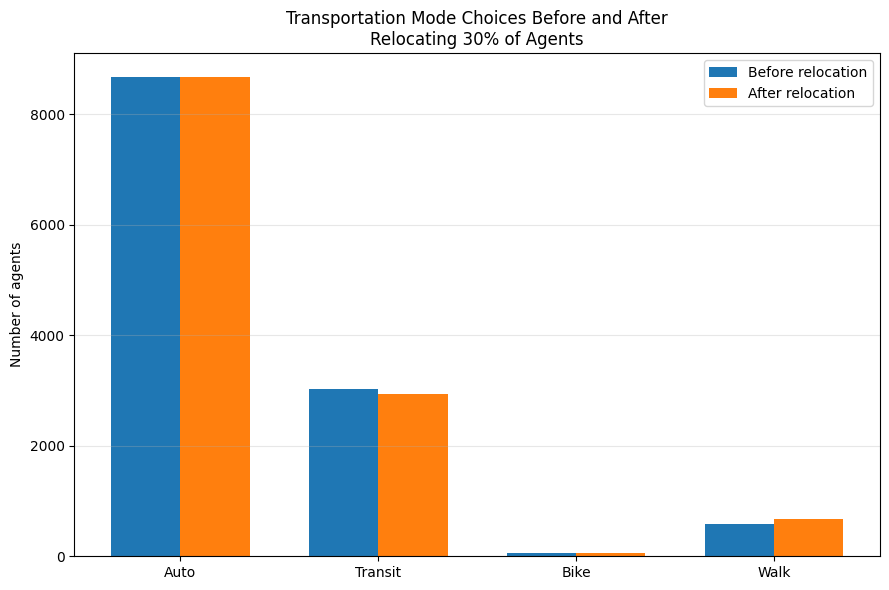

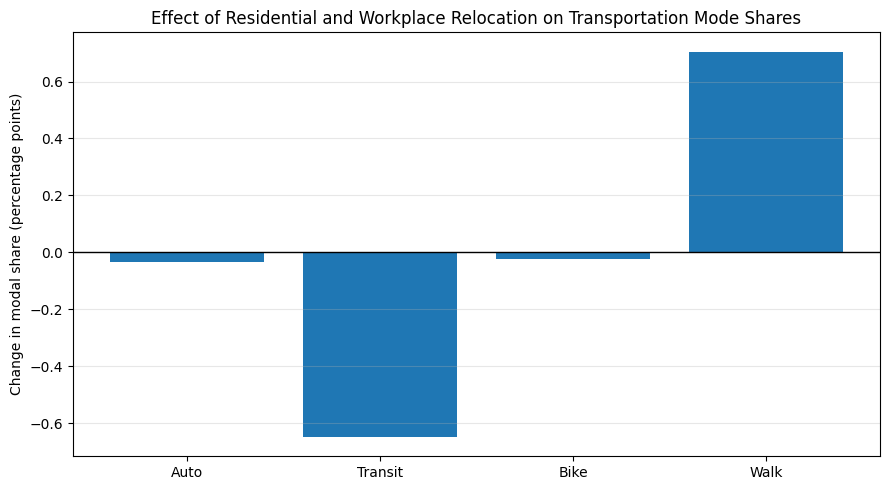

In [17]:
# LOAD OPTIMIZED COEFFICIENTS

Optimized_betas = np.load("/content/drive/MyDrive/Transportation_UrbanHealth/Betas_MediumComplexity.npy")

Transport_model.betas = Optimized_betas

agents = Transport_model.agent_list
n_agents = len(agents)

modes = ["auto", "transit", "bike", "walk"]
mode_labels = ["Auto", "Transit", "Bike", "Walk"]


def run_transport_simulation(model, betas, n_steps=1):

    model.betas = betas

    for step in range(n_steps):
        # Explicitly call custom TransportModel.step()
        TransportModel.model_step(model)

    return np.array([a.mode_choice for a in model.agent_list],dtype=object)


# BASELINE SIMULATION BEFORE RELOCATION


print("\n========== BASELINE SIMULATION ==========")
baseline_choices = run_transport_simulation(Transport_model,Optimized_betas,n_steps=1)

baseline_counts = np.array([np.sum(baseline_choices == mode) for mode in modes])

print("Baseline counts:", baseline_counts)

# RANDOMLY SELECT 30% OF AGENTS

sample_size = int(0.30 * n_agents)
selected_indices = random.sample(range(n_agents), sample_size)
selected_agents = [agents[i] for i in selected_indices]
selected_indices_set = set(selected_indices)
print("\nAgents selected for relocation:", sample_size)


# CHANGE RESIDENTIAL AND WORKPLACE LOCATIONS

# Store original locations
original_locations = {
    i: {
        "res_id": agents[i].res_id,
        "work_id": agents[i].work_id,
        "x": agents[i].x,
        "y": agents[i].y,
        "work_x": agents[i].work_x,
        "work_y": agents[i].work_y
    }
    for i in selected_indices
}

# Keep residential choices restricted to valid residential locations
residential_ids = Transport_model.residential["res_id"].to_numpy()

for i in tqdm(selected_indices,desc="Relocating agents"):

    agent = agents[i]
    old_res_id = agent.res_id

    # Select a different residential location
    # (provided at least two residences exist)
    if len(residential_ids) > 1:
        new_res_id = old_res_id
        while new_res_id == old_res_id:
            new_res_id = random.choice(residential_ids)
    else:
        new_res_id = old_res_id

    agent.res_id = new_res_id


    agent.work_id = None
    agent.work_x = np.nan
    agent.work_y = np.nan

    agent.workplace_node_network = None
    agent.work_stm_node_network = None

    # Assign new home and workplace
    agent.assign_nodes()


# UPDATE LOCAL POPULATION DENSITY

print("\nUpdating local population density...")
Transport_model.assign_local_population_density()


# RECALCULATE TRAVEL TIMES FOR RELOCATED AGENTS

print("\nRecalculating travel times for relocated agents...")

# Reset travel times and availability flags
for agent in selected_agents:

    agent.time_car = np.nan
    agent.time_home_stm = np.nan
    agent.time_stm_stm = np.nan
    agent.time_stm_work = np.nan
    agent.time_bike = np.nan
    agent.time_walk = np.nan

    agent.auto_available = False
    agent.transit_available = False
    agent.bike_available = False
    agent.walk_available = False

# Calculate only once, not inside the five-step loop
Transport_model.compute_all_travel_times(selected_agents)


# UPDATE STATIC CALIBRATION DATA

print("\nUpdating static calibration data...")
Transport_model.prepare_static_calibration_data()


# RUN POST-RELOCATION SIMULATION

print("\n========== POST-RELOCATION SIMULATION ==========")

new_choices = run_transport_simulation(Transport_model,Optimized_betas,n_steps=1)

new_counts = np.array([np.sum(new_choices == mode)for mode in modes])
print("Post-relocation counts:", new_counts)


# COMPARE BEFORE AND AFTER

print("\n========== COMPARISON ==========")

comparison_df = pd.DataFrame({
    "Mode": mode_labels,
    "Before": baseline_counts,
    "After": new_counts,
    "Difference": new_counts - baseline_counts,
    "Before_share": baseline_counts / n_agents,
    "After_share": new_counts / n_agents
})

comparison_df["Change_pp"] = (comparison_df["After_share"]- comparison_df["Before_share"]) * 100
print(comparison_df.round(3))


# INDIVIDUAL TRANSPORTATION MODE TRANSITIONS

transition_df = pd.crosstab(
    pd.Categorical(baseline_choices, categories=modes),
    pd.Categorical(new_choices, categories=modes),
    rownames=["Before"],
    colnames=["After"],
    dropna=False
)

print("\nTransportation mode transition matrix:")
print(transition_df)

# Total number of agents who changed transportation mode
changed_modes = baseline_choices != new_choices

print("\nAgents changing transportation mode:",changed_modes.sum())
print("Percentage changing transportation mode:",round(changed_modes.mean() * 100, 2),"%")


# SEPARATE RELOCATED AND NON-RELOCATED AGENTS

relocated_mask = np.zeros(n_agents, dtype=bool)
relocated_mask[selected_indices] = True

relocated_changed = np.sum(changed_modes & relocated_mask)

non_relocated_changed = np.sum(changed_modes & ~relocated_mask)

print("\nRelocated agents changing mode:", relocated_changed)
print("Percentage of relocated agents changing mode:",round(relocated_changed / sample_size * 100, 2),"%")
print("\nNon-relocated agents changing mode:",non_relocated_changed)
print("Percentage of non-relocated agents changing mode:",round(non_relocated_changed/ (n_agents - sample_size) * 100,2),"%")

# PLOT BEFORE VS AFTER TRANSPORTATION MODE COUNTS

x = np.arange(len(modes))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width / 2,
    baseline_counts,
    width,
    label="Before relocation"
)

plt.bar(
    x + width / 2,
    new_counts,
    width,
    label="After relocation"
)

plt.xticks(x, mode_labels)

plt.ylabel("Number of agents")

plt.title(
    "Transportation Mode Choices Before and After\n"
    "Relocating 30% of Agents"
)

plt.grid(axis="y", alpha=0.3)

plt.legend()
plt.tight_layout()
plt.show()


# PLOT CHANGE IN MODAL SHARES

plt.figure(figsize=(9, 5))

plt.bar(mode_labels,comparison_df["Change_pp"])
plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Change in modal share (percentage points)")
plt.title("Effect of Residential and Workplace Relocation on Transportation Mode Shares")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()